# Guía L2 — El índice sancocho · **Sesión 2: el índice en el tiempo y el duelo de ciudades**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

Hoy la olla se pone histórica: años de precios oficiales, los picos con nombre propio, el duelo de ciudades, la apuesta de conmutatividad y la unidad monetaria más seria jamás inventada: **el sancocho**.

**Antes de ejecutar:** predicciones P4 y P5 de la guía, en papel, foto al informe. P5 es la apuesta central del laboratorio — no se la salten, que sin apuesta no hay gloria.

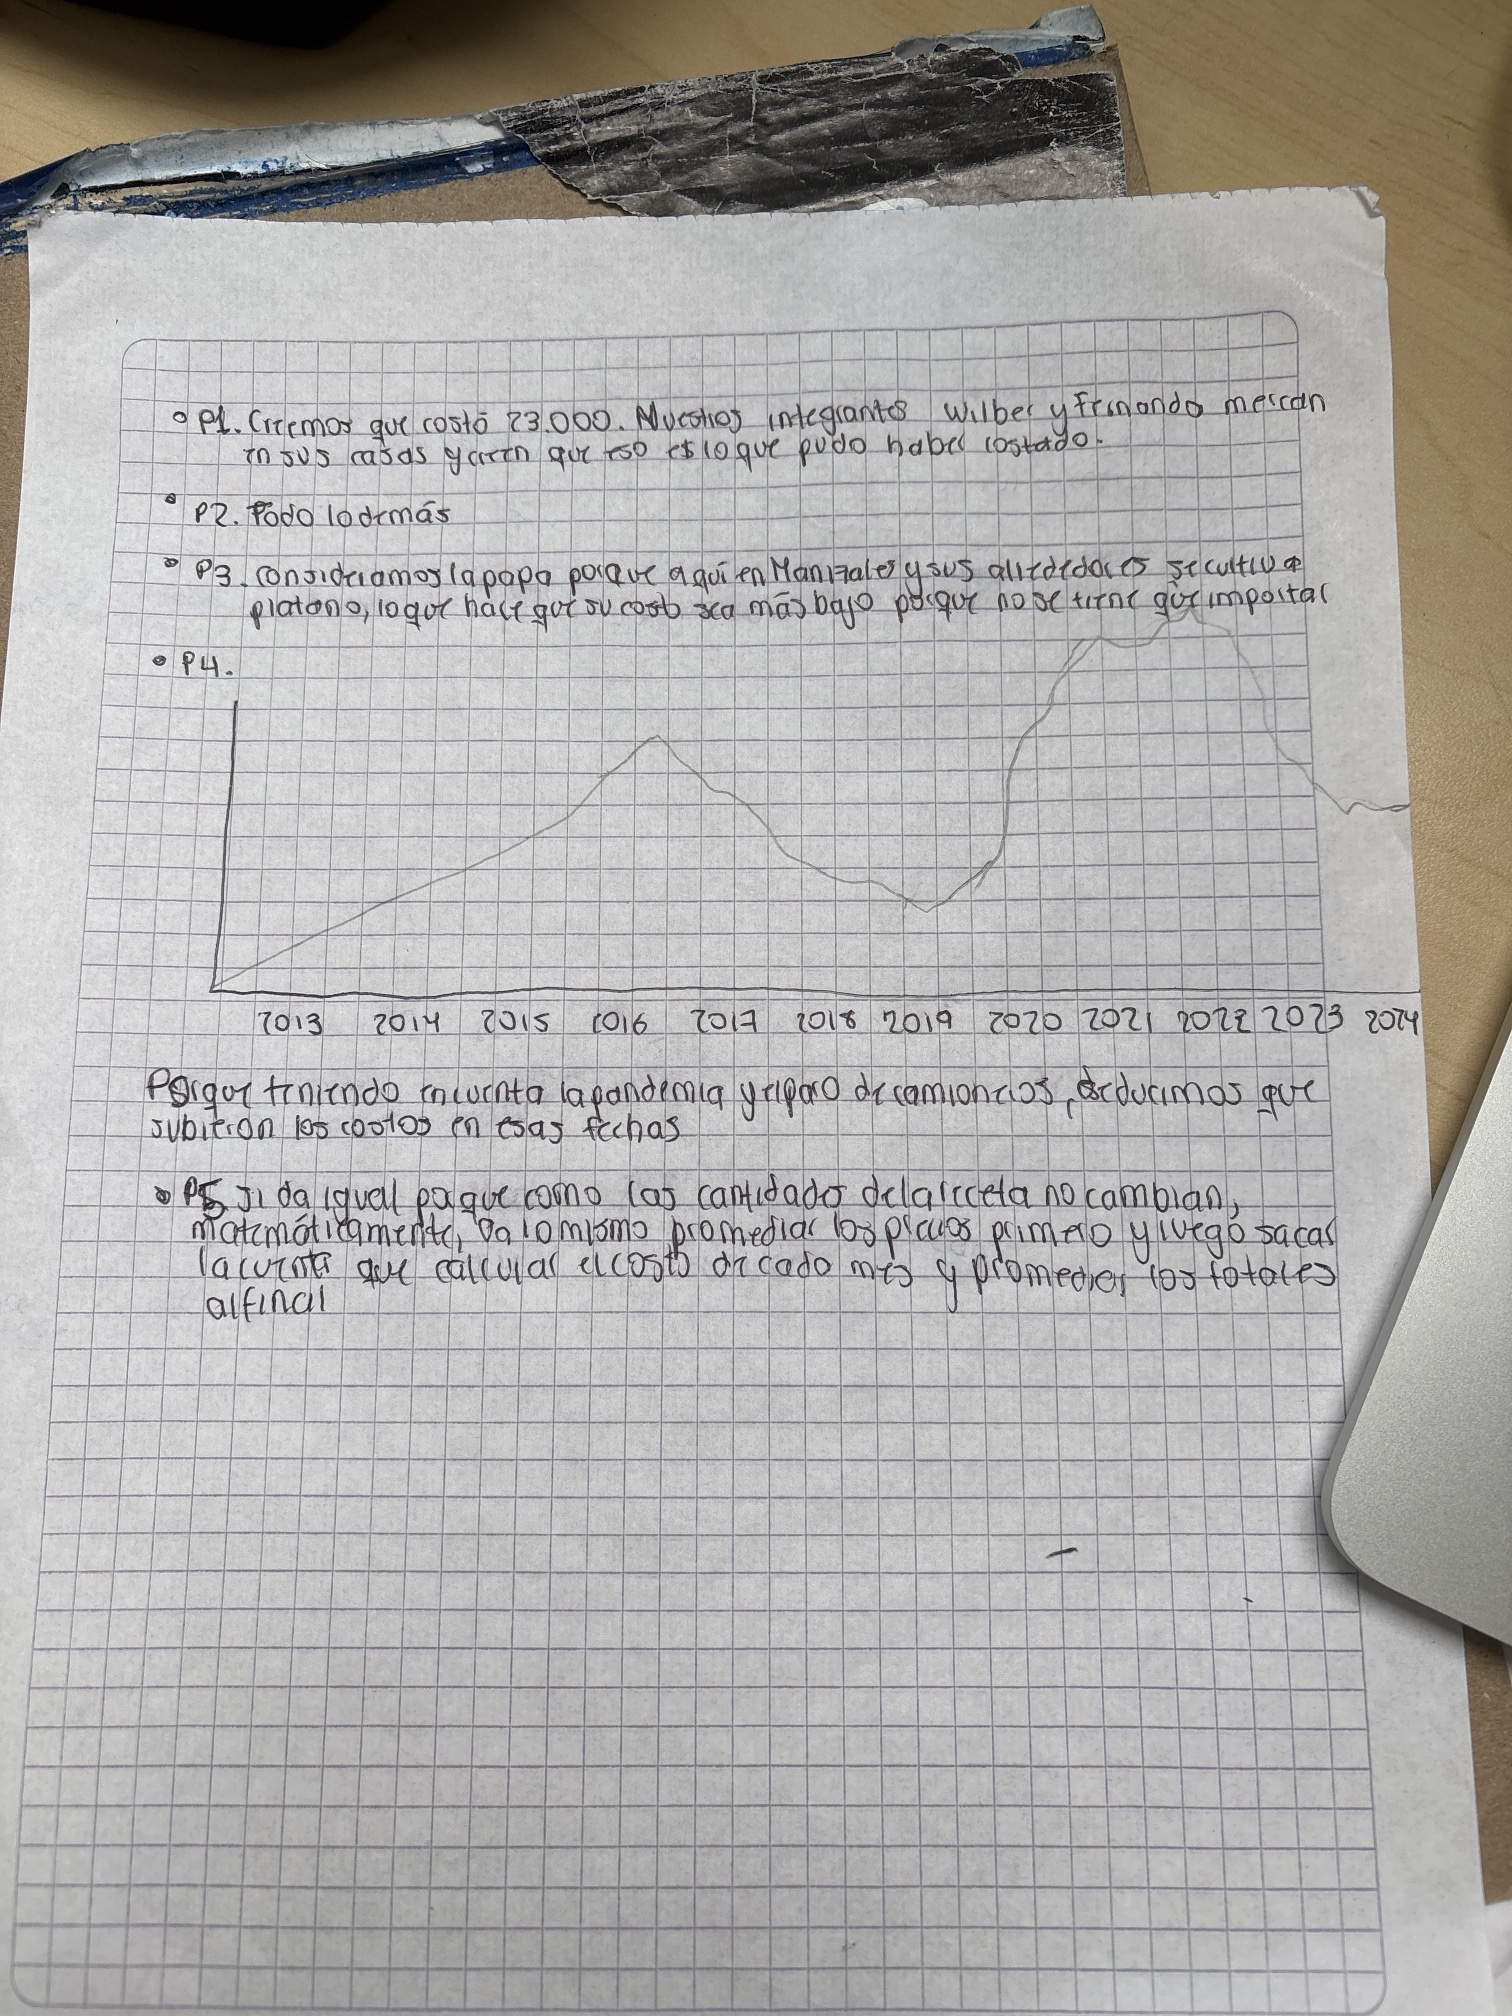

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

RUTA = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main/datos/sipsa_mensual.csv.gz"
df = pd.read_csv(RUTA)

# La receta oficial y el pipeline de la sesión 1 (los reconstruimos aquí para
# que este cuaderno sea autónomo — reproducibilidad ante todo):
RECETA = {
    "Carne de cerdo, espinazo":       1.5,
    "Yuca ICA":                       1.0,
    "Papa capira":                    1.0,
    "Chócolo mazorca":                0.9,
    "Plátano dominico hartón verde":  1.4,
}

def indice_plato(tabla, ciudad, receta):
    "tabla -> serie: costo del plato mes a mes en una ciudad. El pipeline entero, empacado."
    # Si hay varias centrales en la ciudad, se usa su promedio simple por producto y mes.
    t = tabla[(tabla["ciudad"] == ciudad) & (tabla["producto"].isin(receta))]
    p = t.pivot_table(index="fecha", columns="producto", values="precio_kg", aggfunc="mean")
    faltantes = [producto for producto in receta if producto not in p.columns]
    if faltantes:
        raise ValueError(f"{ciudad}: faltan ingredientes de la receta: {faltantes}")
    p = p[list(receta)]
    meses_incompletos = p.index[p.isna().any(axis=1)].to_list()
    if meses_incompletos:
        raise ValueError(f"{ciudad}: receta incompleta en {len(meses_incompletos)} meses; primero revisen la sustitución.")
    return p.mul(pd.Series(receta), axis="columns").sum(axis=1)

print("Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta.",
      "Nada global. Cambiar de plato será cambiar un diccionario.")

Pipeline listo. Fíjense: indice_plato RECIBE la tabla, la ciudad y la receta. Nada global. Cambiar de plato será cambiar un diccionario.


---
## 1 · El índice sancocho, 2013 en adelante

Confronten con su P4: ¿la curva que bosquejaron se parece a la real?

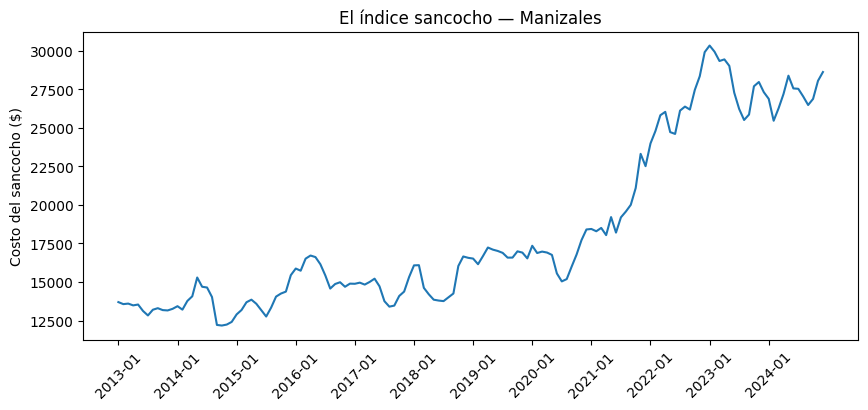

Primer mes (2013-01): $13,695
Último mes (2024-12): $28,634
Variación total: 109.1%


In [ ]:
sancocho_mzl = indice_plato(df, "Manizales", RECETA)

plt.figure(figsize=(10, 4))
plt.plot(range(len(sancocho_mzl)), sancocho_mzl.values)
paso = 12
plt.xticks(range(0, len(sancocho_mzl), paso), sancocho_mzl.index[::paso], rotation=45)
plt.ylabel("Costo del sancocho ($)")
plt.title("El índice sancocho — Manizales")
plt.show()

print(f"Primer mes ({sancocho_mzl.index[0]}): ${sancocho_mzl.iloc[0]:,.0f}")
print(f"Último mes ({sancocho_mzl.index[-1]}): ${sancocho_mzl.iloc[-1]:,.0f}")
print(f"Variación total: {100*(sancocho_mzl.iloc[-1]/sancocho_mzl.iloc[0]-1):.1f}%")

In [ ]:
# Los saltos más bruscos, en porcentaje frente al mes anterior.
cambio = sancocho_mzl.pct_change() * 100
print("Mayores subidas:\n", cambio.sort_values(ascending=False).head(4).round(1).to_string())
print("\nMayores caídas:\n", cambio.sort_values().head(2).round(1).to_string())

# ¿Qué ingrediente explica cada salto? Aporte en pesos, y papa capira en otras ciudades.
precios = (df[(df["ciudad"] == "Manizales") & df["producto"].isin(RECETA)]
           .pivot_table(index="fecha", columns="producto", values="precio_kg"))[list(RECETA)]
for antes, despues in [("2018-09", "2018-10"), ("2021-10", "2021-11")]:
    aporte = (precios.loc[despues] - precios.loc[antes]) * pd.Series(RECETA)
    print(f"\n{antes} -> {despues}: sube ${aporte.sum():,.0f}")
    print(aporte.round(0).sort_values(ascending=False).to_string())
    papa = df[(df["producto"] == "Papa capira") & df["ciudad"].isin(["Manizales", "Medellín", "Pereira", "Cali", "Armenia"])
              & df["fecha"].isin([antes, despues])].pivot_table(index="ciudad", columns="fecha", values="precio_kg")
    print("Papa capira, cambio %:", (100 * (papa[despues] / papa[antes] - 1)).round(1).to_dict())

Mayores subidas:
 fecha
2018-10    12.5
2021-11    10.5
2014-05     8.7
2015-12     7.4

Mayores caídas:
 fecha
2014-09   -12.9
2018-03    -9.1

2018-09 -> 2018-10: sube $1,786
producto
Carne de cerdo, espinazo         1125.0
Plátano dominico hartón verde     315.0
Papa capira                       185.0
Yuca ICA                          156.0
Chócolo mazorca                     5.0
Papa capira, cambio %: {'Armenia': 20.4, 'Cali': 31.9, 'Manizales': 27.0, 'Medellín': 22.5, 'Pereira': 26.2}

2021-10 -> 2021-11: sube $2,218
producto
Carne de cerdo, espinazo         1500.0
Yuca ICA                          362.0
Papa capira                       257.0
Chócolo mazorca                   126.0
Plátano dominico hartón verde     -27.0
Papa capira, cambio %: {'Cali': 21.7, 'Manizales': 22.9, 'Medellín': 21.3, 'Pereira': 21.9}


🗣️ **Los picos tienen nombre.** Elijan los **dos** saltos más bruscos de la curva. Para cada uno: ¿en qué mes ocurre?, ¿qué pasó en Colombia por esas fechas? (Pistas de historiador: paros, fenómenos de El Niño o La Niña, cosechas, tasa de cambio. Busquen — con IA si quieren, documentando — y sustenten: hipótesis + evidencia, tres líneas por pico.)

Tomamos las dos mayores **subidas** en porcentaje. La mayor caída fue en 2014-09 (−12,9 %), y la dejamos por fuera porque buscamos picos al alza.

**Pico 1: octubre de 2018 (+12,5 %, de $14.253 a $16.040).** *Hipótesis:* se juntaron un fin de cosechas de papa y un alza local del cerdo. *Evidencia:* el boletín SIPSA de ese mes reporta alzas de papa capira en los 29 mercados donde se negoció, por el fin de las cosechas; en nuestros datos sube entre 20 % y 32 % en cinco ciudades. Pero el mayor aporte fue el espinazo ($1.125 de $1.786), y ese precio no subió en Medellín, Pereira, Cali ni Ibagué, así que parece algo de Manizales. No encontramos la causa de eso. [Boletín DANE](https://www.dane.gov.co/files/investigaciones/agropecuario/sipsa/Bol_mensual_oct_2018.pdf)

**Pico 2: noviembre de 2021 (+10,5 %, de $21.103 a $23.321).** *Hipótesis:* las lluvias de La Niña redujeron la oferta de perecederos en un año de alimentos ya caros. *Evidencia:* BBVA Research atribuye el alza de perecederos de ese mes a la menor oferta por La Niña; el boletín SIPSA reporta que las lluvias afectaron la recolección de papa, y en nuestros datos la papa capira sube cerca de 22 % en cuatro ciudades. La yuca también subió, pero otra vez el mayor aporte fue el espinazo ($1.500 de $2.218), que estas fuentes no explican. El paro nacional de 2021 fue en abril a junio, así que no explica este salto. [BBVA Research](https://www.bbvaresearch.com/publicaciones/colombia-los-alimentos-llevan-la-inflacion-en-noviembre-al-526/) · [Boletín DANE](https://www.dane.gov.co/files/investigaciones/agropecuario/sipsa/Bol_mensual_SIPSA_mayoristas_nov_2021.pdf)

---
## 2 · El duelo de ciudades (y el problema de la sustitución)

El sancocho "igual" no existe entre ciudades: el conjunto oficial obliga a decidir **equivalencias** de variedades y cortes. Además, cuando hay varias centrales en una ciudad, `indice_plato` usa el promedio simple de sus observaciones disponibles por producto y mes. El cuaderno trae una receta base que funciona los 144 meses; no es una verdad culinaria. Ambas son decisiones de modelación: defiéndanlas.

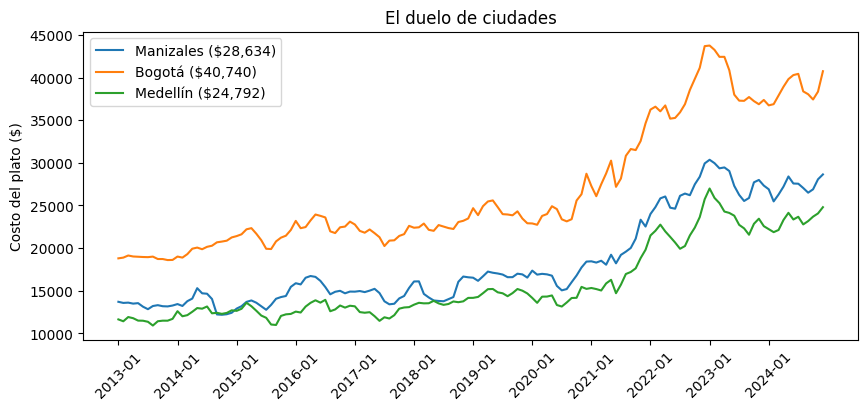

,inicio,final,aumento en pesos,aumento porcentual
Manizales,13695.0,28634.0,14939.0,109.1
Bogotá,18791.0,40740.0,21949.0,116.8
Medellín,11631.0,24792.0,13161.0,113.2


In [ ]:
# ✏️ Ejercicio 1 — Revisen las equivalencias y, si las cambian, defiendan la decisión.
# Pista: df[(df.ciudad=="Bogotá") & (df.producto.str.contains("yuca", case=False))]["producto"].unique()

RECETA_BOGOTA = {
    "Carne de cerdo, costilla":    1.5,   # sustitución del espinazo
    "Yuca llanera":               1.0,
    "Papa parda pastusa":         1.0,
    "Chócolo mazorca":            0.9,
    "Plátano hartón verde":       1.4,
}

RECETA_MEDELLIN = {
    "Carne de cerdo, espinazo":  1.5,
    "Yuca criolla":              1.0,   # sustitución de Yuca ICA
    "Papa capira":               1.0,
    "Chócolo mazorca":           0.9,
    "Plátano hartón verde":      1.4,   # sustitución del dominico hartón
}

series = {
    "Manizales": sancocho_mzl,
    "Bogotá":    indice_plato(df, "Bogotá", RECETA_BOGOTA),
    "Medellín":  indice_plato(df, "Medellín", RECETA_MEDELLIN),
}

plt.figure(figsize=(10, 4))
for ciudad, s in series.items():
    plt.plot(range(len(s)), s.values, label=f"{ciudad} (${s.iloc[-1]:,.0f})")
plt.xticks(range(0, len(sancocho_mzl), 12), sancocho_mzl.index[::12], rotation=45)
plt.ylabel("Costo del plato ($)")
plt.title("El duelo de ciudades")
plt.legend()
plt.show()

comparacion = pd.DataFrame({
    ciudad: {"inicio": serie.iloc[0], "final": serie.iloc[-1]}
    for ciudad, serie in series.items()
}).T
comparacion["aumento en pesos"] = comparacion["final"] - comparacion["inicio"]
comparacion["aumento porcentual"] = 100 * (comparacion["final"] / comparacion["inicio"] - 1)
comparacion.round({"inicio": 0, "final": 0, "aumento en pesos": 0, "aumento porcentual": 1})

In [ ]:
# Dos pruebas más. 1) Promedio de todo el primer y último año, menos sensible a un mes raro.
for ciudad, serie in series.items():
    promedio_2013 = serie[serie.index.str.startswith("2013")].mean()
    promedio_2024 = serie[serie.index.str.startswith("2024")].mean()
    subida_pesos = promedio_2024 - promedio_2013
    subida_porcentaje = 100 * (promedio_2024 / promedio_2013 - 1)
    print(f"{ciudad}: 2013 ${promedio_2013:,.0f} -> 2024 ${promedio_2024:,.0f} | +${subida_pesos:,.0f} | +{subida_porcentaje:.1f}%")

# 2) El mismo plato sin la carne, porque Bogotá usa costilla y las otras dos usan espinazo.
recetas = {"Manizales": RECETA, "Bogotá": RECETA_BOGOTA, "Medellín": RECETA_MEDELLIN}
print("\nCosto en 2024-12 sin carne:")
for ciudad, receta in recetas.items():
    sin_carne = {}
    for producto in receta:
        if not producto.startswith("Carne"):
            sin_carne[producto] = receta[producto]
    costo = indice_plato(df, ciudad, sin_carne).iloc[-1]
    print(f"{ciudad}: ${costo:,.0f}")

Manizales: 2013 $13,325 -> 2024 $27,207 | +$13,882 | +104.2%
Bogotá: 2013 $18,856 -> 2024 $38,657 | +$19,801 | +105.0%
Medellín: 2013 $11,501 -> 2024 $23,259 | +$11,758 | +102.2%

Costo en 2024-12 sin carne:
Manizales: $8,384
Bogotá: $8,871
Medellín: $9,582


🗣️ **Tabla de equivalencias (escriban aquí):** Manizales: espinazo / Yuca ICA / papa capira / dominico hartón; Bogotá: costilla / yuca llanera / parda pastusa / hartón; Medellín: espinazo / yuca criolla / capira / hartón. Defiendan en tres líneas por qué estas sustituciones permiten comparar platos sin fingir que son idénticos.

¿Dónde es más caro el almuerzo y por cuánto? ¿Las curvas suben al mismo ritmo? Y la pregunta con trampa: **"¿dónde subió más?" tiene dos respuestas legítimas** — en pesos y en porcentaje. Calculen ambas y decidan cuál reportarían, defendiendo la elección. **Defensa de las equivalencias.** Elegimos en cada ciudad la variedad más cercana con dato en los 144 meses. En Bogotá el espinazo solo aparece en 67 meses, por eso se usa costilla. Las sustituciones permiten comparar el mismo tipo de almuerzo, pero no el mismo plato: Bogotá paga un corte distinto, y Medellín promedia su central mayorista con una plaza minorista.

**¿Dónde es más caro?** En diciembre de 2024, Bogotá: $40.740, frente a $28.634 en Manizales ($12.106 más) y $24.792 en Medellín. Pero casi toda esa ventaja viene de la costilla: sin carne, Bogotá cuesta $8.871, Manizales $8.384 y Medellín $9.582, la más cara.

**¿Suben al mismo ritmo?** Casi. Hay diferencias de un mes a otro, pero con el promedio de cada año (2013 contra 2024) las tres crecen parecido: Bogotá +105,0 %, Manizales +104,2 % y Medellín +102,2 %.

**¿Dónde subió más?** Del primer al último mes, Bogotá gana en las dos medidas: +$21.949 y +116,8 %. Reportaríamos el porcentaje con promedios anuales: Bogotá sube más pesos sobre todo porque arranca más cara, y los promedios dependen menos de un mes raro.

---
## 3 · La apuesta central: ¿conmutan?

P5 sobre la mesa. Dos caminos para el "costo típico anual" del sancocho:

- **Camino A:** promediar los 12 precios del año de cada ingrediente → costear la receta una vez.
- **Camino B:** costear la receta mes a mes → promediar los 12 costos.

¿Dan lo mismo? Primero su apuesta escrita, luego el juez:

In [ ]:
AÑO = "2016"
mzl = df[(df["ciudad"] == "Manizales") & (df["producto"].isin(RECETA))]
anual = mzl[mzl["fecha"].str.startswith(AÑO)]

# Camino A: promediar precios, luego costear
precios_promedio = anual.groupby("producto")["precio_kg"].mean()
camino_A = sum(RECETA[p] * precios_promedio[p] for p in RECETA)

# Camino B: costear cada mes, luego promediar
camino_B = indice_plato(df, "Manizales", RECETA)
camino_B = camino_B[camino_B.index.str.startswith(AÑO)].mean()

print(f"Camino A (promediar → costear): ${camino_A:,.2f}")
print(f"Camino B (costear → promediar): ${camino_B:,.2f}")
print(f"Diferencia: ${abs(camino_A - camino_B):.6f}")

Camino A (promediar → costear): $15,587.53
Camino B (costear → promediar): $15,587.53
Diferencia: $0.000000


In [ ]:
# ✏️ Ejercicio 2 — Rompan la magia.
# Repitan los dos caminos usando la MEDIANA en lugar del promedio.
# ¿Siguen dando lo mismo? ¿Y si antes de promediar eliminan el 5% de precios más caros?

meses_anual = anual.pivot_table(index="fecha", columns="producto", values="precio_kg")[list(RECETA)]
kilos = pd.Series(RECETA)

camino_A_mediana = (meses_anual.median() * kilos).sum()       # mediana de precios -> costear
camino_B_mediana = (meses_anual * kilos).sum(axis=1).median() # costear -> mediana de costos
print(f"Mediana, camino A: ${camino_A_mediana:,.2f}")
print(f"Mediana, camino B: ${camino_B_mediana:,.2f}")
print(f"Diferencia: ${abs(camino_A_mediana - camino_B_mediana):,.2f}")

# Quitar el 5 % más caro: en A se quitan precios de cada producto; en B, costos mensuales.
def sin_caros(serie):
    return serie[serie <= serie.quantile(0.95)]

camino_A_filtro = 0
for producto in RECETA:
    camino_A_filtro = camino_A_filtro + RECETA[producto] * sin_caros(meses_anual[producto]).mean()
camino_B_filtro = sin_caros((meses_anual * kilos).sum(axis=1)).mean()
print(f"\nFiltro 5 %, camino A: ${camino_A_filtro:,.2f}")
print(f"Filtro 5 %, camino B: ${camino_B_filtro:,.2f}")
print(f"Diferencia: ${abs(camino_A_filtro - camino_B_filtro):,.2f}")

# Ejemplo pequeño: dos ingredientes en tres meses.
a = pd.Series([1, 2, 9]); b = pd.Series([9, 1, 2])
print("\npromedio(a) + promedio(b) =", a.mean() + b.mean(), "| promedio(a + b) =", (a + b).mean())
print("mediana(a) + mediana(b) =", a.median() + b.median(), "| mediana(a + b) =", (a + b).median())

# 🗣️ Moraleja: los dos caminos coinciden con el promedio porque la receta es lineal (una suma
# de precios por constantes) y el promedio también lo es; con la mediana se rompe porque la
# mediana no es lineal: la mediana de una suma no es la suma de las medianas.
# En 2016 los caminos con promedio solo difieren en el redondeo del computador, no en la matemática.

Mediana, camino A: $15,643.55
Mediana, camino B: $15,580.50
Diferencia: $63.05

Filtro 5 %, camino A: $15,451.83
Filtro 5 %, camino B: $15,484.67
Diferencia: $32.84

promedio(a) + promedio(b) = 8.0 | promedio(a + b) = 8.0
mediana(a) + mediana(b) = 4.0 | mediana(a + b) = 10.0


---
## 4 · El camino de regreso: la unidad sancocho

Del costo total del plato no se puede recuperar el precio del plátano — la suma colapsa infinitas combinaciones en un número (no inyectiva: información que muere). Pero hay una conversión que sí tiene camino de regreso perfecto:

In [ ]:
VALOR_SANCOCHO = float(sancocho_mzl.iloc[-1])   # 1 sancocho = costo del último mes del congelado

def a_sancochos(pesos):
    return pesos / VALOR_SANCOCHO

def a_pesos(sancochos):
    return sancochos * VALOR_SANCOCHO

# La prueba de fuego de una inversa: ida y vuelta = quedarse quieto.
print("¿a_pesos(a_sancochos(x)) == x?  →", a_pesos(a_sancochos(123456.0)))

¿a_pesos(a_sancochos(x)) == x?  → 123456.00000000001


In [ ]:
# ✏️ Ejercicio 3 — Conviertan a sancochos: el salario mínimo de ese año, la matrícula,
# y la mesada (o el presupuesto mensual de comida) de alguien del equipo que quiera confesarla.
# Fuentes: Decreto 2738 de 2012 (año 2013) y Decreto 2292 de 2023 (año 2024).
SALARIO_MINIMO_2013 = 589_500
SALARIO_MINIMO = 1_300_000    # 2024, último año del dataset
print(f"El salario mínimo de 2024 equivale a {a_sancochos(SALARIO_MINIMO):.1f} sancochos")

MATRICULA = 380_000
MESADA = 400_000
for nombre, valor in [("La matrícula", MATRICULA), ("La mesada", MESADA)]:
    if valor is not None:
        print(f"{nombre} equivale a {a_sancochos(valor):.1f} sancochos")

# Poder adquisitivo: cada salario con el costo promedio de SU propio año.
costo_2013 = sancocho_mzl[sancocho_mzl.index.str.startswith("2013")].mean()
costo_2024 = sancocho_mzl[sancocho_mzl.index.str.startswith("2024")].mean()
print(f"2013: {SALARIO_MINIMO_2013 / costo_2013:.1f} sancochos | 2024: {SALARIO_MINIMO / costo_2024:.1f} sancochos")

# 🗣️ ¿Y la pregunta incómoda: el salario mínimo de 2013 alcanzaba para más o menos
# sancochos que el del último año del dataset? Calcúlenlo. Eso — poder adquisitivo
# medido en almuerzos — es economía seria con matemáticas de primer semestre.
# Respuesta: alcanzaba para menos. Con el costo promedio de cada año, 44,2 sancochos en 2013
# contra 47,8 en 2024, unos 8 % más. El salario subió un poco más que este plato, aunque esto
# usa precios mayoristas y no incluye arriendo, transporte ni otros gastos.

El salario mínimo de 2024 equivale a 45.4 sancochos
La matrícula equivale a 13.3 sancochos
La mesada equivale a 14.0 sancochos
2013: 44.2 sancochos | 2024: 47.8 sancochos


---
## 5 · El plato propio (proyecto del equipo)

Cambiar de plato es cambiar un diccionario — esa es la recompensa de haber escrito el pipeline como funciones. Elijan SU plato (ajiaco, mondongo, frijolada, o la receta de su casa con las cantidades que les dicte quien cocina) y construyan su índice.

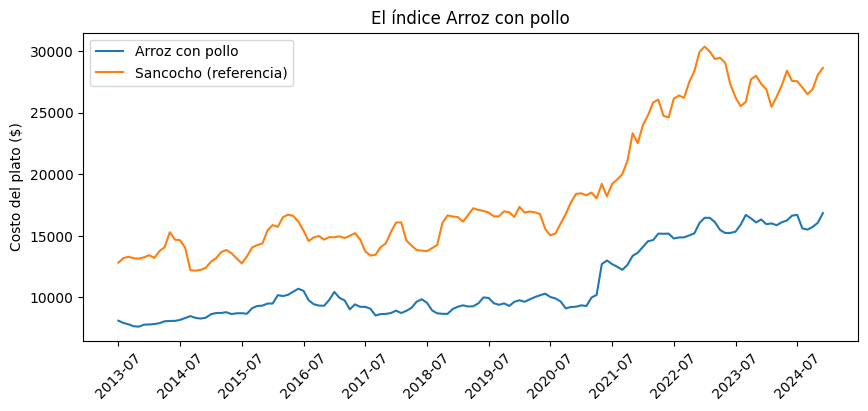

Arroz con pollo: $8,114 -> $16,849 (x2.08)
Sancocho: $12,828 -> $28,634 (x2.23)
       Arroz con pollo  Sancocho
fecha                           
2013              0.96      1.03
2014              1.00      1.05
2015              1.10      1.07
2016              1.23      1.22
2017              1.14      1.13
2018              1.12      1.17
2019              1.17      1.31
2020              1.20      1.30
2021              1.45      1.54
2022              1.85      2.04
2023              1.97      2.18
2024              1.98      2.12
La pechuga aporta $11,156: 66% del plato en 2024-12


In [ ]:
# ✏️ Ejercicio 4 — Su plato, su índice.
# Receta de arroz con pollo para seis personas. Los kilos son equivalencias aproximadas.
# Pechuga 750 g | arroz 3 tazas = 0,6 kg | cebolla cabezona 1 grande = 0,25 kg
# cebolla larga 3 tallos = 0,15 kg | pimentón 1 grande = 0,2 kg | ajo 3 dientes = 0,015 kg
# tomate 2 grandes = 0,3 kg | habichuela 1/2 taza = 0,05 kg
# maíz tierno 1/2 taza = 0,15 kg de chócolo mazorca | cilantro = 0,02 kg
RECETA_PROPIA = {
    "Pechuga de pollo":        0.75,
    "Arroz de primera":        0.6,
    "Cebolla cabezona blanca": 0.25,
    "Cebolla junca":           0.15,
    "Pimentón":                0.2,
    "Ajo":                     0.015,
    "Tomate chonto":           0.3,
    "Habichuela":              0.05,
    "Chócolo mazorca":         0.15,
    "Cilantro":                0.02,
}
NOMBRE_PLATO = "Arroz con pollo"
CIUDAD_PROPIA = "Manizales"

# Decisiones: empezamos en 2013-07 porque antes no hay precio de pechuga.
# Solo entran ingredientes con precio todos los meses desde entonces. Por eso quedan fuera
# zanahoria, arveja, aceite y salsa de tomate. Tampoco entran sazonador, sal y pimienta.
df_propio = df[df["fecha"] >= "2013-07"]

if RECETA_PROPIA:
    mi_indice = indice_plato(df_propio, CIUDAD_PROPIA, RECETA_PROPIA)
    sancocho_comun = sancocho_mzl.loc[mi_indice.index]   # mismos meses para poder comparar

    plt.figure(figsize=(10, 4))
    plt.plot(range(len(mi_indice)), mi_indice.values, label=NOMBRE_PLATO)
    plt.plot(range(len(sancocho_comun)), sancocho_comun.values, label="Sancocho (referencia)")
    plt.xticks(range(0, len(mi_indice), 12), mi_indice.index[::12], rotation=45)
    plt.ylabel("Costo del plato ($)")
    plt.legend()
    plt.title(f"El índice {NOMBRE_PLATO}")
    plt.show()

    # ¿Su plato se infló más o menos que el sancocho? ¿En qué años se separan las curvas?
    print(f"{NOMBRE_PLATO}: ${mi_indice.iloc[0]:,.0f} -> ${mi_indice.iloc[-1]:,.0f} (x{mi_indice.iloc[-1] / mi_indice.iloc[0]:.2f})")
    print(f"Sancocho: ${sancocho_comun.iloc[0]:,.0f} -> ${sancocho_comun.iloc[-1]:,.0f} (x{sancocho_comun.iloc[-1] / sancocho_comun.iloc[0]:.2f})")

    base = pd.DataFrame({NOMBRE_PLATO: mi_indice / mi_indice.iloc[0], "Sancocho": sancocho_comun / sancocho_comun.iloc[0]})
    print(base.groupby(base.index.str[:4]).mean().round(2))

    pechuga = RECETA_PROPIA["Pechuga de pollo"] * df_propio[(df_propio["ciudad"] == "Manizales") &
              (df_propio["producto"] == "Pechuga de pollo") & (df_propio["fecha"] == "2024-12")]["precio_kg"].iloc[0]
    print(f"La pechuga aporta ${pechuga:,.0f}: {100 * pechuga / mi_indice.iloc[-1]:.0f}% del plato en 2024-12")
    # 🗣️ El arroz con pollo se infló menos: desde julio de 2013 se multiplicó por 2,08 y el sancocho
    # por 2,23. Medidas desde ese mes, las dos van casi juntas hasta 2017; desde 2018 el sancocho
    # queda por encima. En los dos platos manda la carne: la pechuga pesa 66 % y el espinazo 71 %.
    # Ojo: $16.849 no es el plato completo. Lo que dejamos fuera costaba unos $5.258 en 2024-12.
    # Con esos ingredientes, en los meses con datos, el plato se multiplica por 1,97: la conclusión se mantiene.

---
## 6 · Momento 3 — Explicar + la cacería estrella

**P4.** Bosquejamos una curva que subía hasta 2016, bajaba hasta 2019, subía fuerte desde 2020 hasta 2022 y caía en 2023 y 2024. Pensábamos en la pandemia y el paro de camioneros. Acertamos el pico de 2016 (16.719 en abril) y la gran subida reciente. Las diferencias fueron tres: 2019 no fue un punto bajo, sino uno de los años altos de ese periodo; a mediados de 2020 el índice bajó (15.039 en julio) antes de subir; y el máximo llegó en enero de 2023 (30.354). Después bajó a 25.471 en febrero de 2024, pero subió otra vez hasta 28.634 en diciembre de 2024.

**(1) Conmutatividad.** Apostamos que sí daba igual, porque las cantidades de la receta no cambian, y acertamos. La IA dijo que los dos caminos dan lo mismo, por la propiedad distributiva y porque se puede cambiar el orden de las sumas. El juez dio lo mismo con el promedio en 2016: 15.587,53 por los dos caminos. Con la mediana dio 15.643,55 contra 15.580,50, y con el filtro del 5 %, 15.451,83 contra 15.484,67. La propiedad es la **linealidad**: la receta y el promedio son lineales, y por eso se puede cambiar el orden. La mediana y el filtro no lo son.

**(2) Invertibilidad.**

| Paso | ¿Tiene regreso? | Por qué |
|---|---|---|
| `filtrar_ciudad`, `filtrar_mes`, `filtrar_productos` | No | Borran filas: de la salida no se recuperan las demás |
| Promediar centrales con `mean` | No | Muchas combinaciones de precios dan el mismo promedio |
| `costear` | No | La suma colapsa infinitas combinaciones en un número: no es inyectiva |
| Unidades de cocina a kilos | Sí, si el factor es fijo | Se divide por 0,3 kg, aunque el peso real de cada mazorca varía |
| Pesos a sancochos | Sí | Es una biyección: se multiplica por una constante distinta de cero |

Esto también importa para auditar: si un índice sale raro, con solo el total no se sabe qué ingrediente falló, hay que conservar la tabla de entrada.

**(3) Picos.** Octubre de 2018 (+12,5 %) y noviembre de 2021 (+10,5 %). En los dos, la papa subió en varias ciudades, con razones reportadas de oferta y clima, pero el mayor aporte en pesos fue el espinazo en Manizales. La causa de ese movimiento queda sin demostrar.

**(4) Duelo.** Bogotá es la más cara ($40.740), pero casi toda su ventaja viene de usar costilla. En porcentaje con promedios anuales, las tres suben casi igual (de 102 % a 105 %). La tabla de equivalencias y su defensa están en la sección 2.

## 🤖 Conjetura y juez

Preguntamos a otra IA si los dos caminos daban lo mismo, cuando el cuaderno ya estaba ejecutado. Dijo que sí, por la propiedad distributiva y el cambio de orden de las sumas. No usó la palabra «linealidad», pero su razón es la misma idea: la receta es una suma de precios por cantidades fijas. El juez confirmó que acertó: 15.587,53 por los dos caminos en 2016. No mencionó que con la mediana se rompe.

🤖 **Y el cierre de la cacería estrella:** en la sesión 1 le preguntaron a su IA cuánto cuesta un sancocho para seis.

Respuesta de la IA, 5 de noviembre de 2026: entre 65.000 y 100.000 en el resumen, 52.500 en su tabla y 70.000 como recomendación.

Veredicto: no son cifras comparables. La IA usó pollo, precios al detal de 2026 y más ingredientes; nuestro índice usa espinazo y precios mayoristas de diciembre de 2024. Por eso es lógico que su cifra sea más alta. Pero nuestro número viene de una fuente y una receta que se pueden revisar, mientras que la IA dio varias cifras distintas y sus precios son aproximados. Nosotros teníamos la cifra; la IA, un buen estimado sin una cifra única.

**Entregables:** cuaderno ejecutado completo + bitácora individual + tarea puente (verificación reproducida y defensa del precio medio). Rúbrica en la guía. Cuaderno que no ejecuta: se devuelve sin calificar.